In [1]:
import os
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Load Dataset
PATH = "dataset/"
CLASS_NAMES = os.listdir(PATH)
print("Classes: ", CLASS_NAMES)

Classes:  ['Broccoli', 'Carrot', 'Cucumber', 'Tomato']


In [3]:
# Load Image
rows, cols = 224, 224

x, y = [],[]

counter = 0

for class_name in CLASS_NAMES:
    for img_name in os.listdir(PATH + class_name):
        path = f"{PATH}{class_name}/{img_name}"
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(rows, cols), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
    counter += 1
    print(class_name)

x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

print("x: ", x.shape)
print("y: ", y.shape)

Broccoli
Carrot
Cucumber
Tomato
x:  (2000, 224, 224, 1)
y:  (2000,)


In [4]:
# Splitting
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, )

In [5]:
# Preprocessing OHE
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)

In [6]:
# DCNN Model Architecture
model = keras.Sequential([
    # Input Layer
    keras.layers.Input(shape=(rows, cols, 1)),

    # Hidden layer: feature extraction
    keras.layers.Conv2D(6, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Flatten(),

    # Output layer: ReLu + Softmax
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(4, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 220, 220, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 106, 106, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,003,512 (19.09 MB)

 Trainable params: 5,003,512 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=10, batch_size=32)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.5138 - loss: 1.0750 - val_accuracy: 0.7500 - val_loss: 0.6899
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.8169 - loss: 0.4978 - val_accuracy: 0.8600 - val_loss: 0.4243
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.8950 - loss: 0.2951 - val_accuracy: 0.8550 - val_loss: 0.4048
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.8838 - loss: 0.2909 - val_accuracy: 0.8800 - val_loss: 0.3669
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9344 - loss: 0.1745 - val_accuracy: 0.8000 - val_loss: 0.5489
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.9600 - loss: 0.1156 - val_accuracy: 0.8900 - val_loss: 0.3962
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - accuracy: 0.9769 - loss: 0.0618 - val_accuracy: 0.8900 - val_loss: 0.4169
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.9556 - loss: 0.1208 - val_accuracy: 0.

In [8]:
# Model Evaluation
model.evaluate(x_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8450 - loss: 0.5379


[0.5379441976547241, 0.8450000286102295]

In [9]:
pred_result = model.predict(x_test)

for i, prediction in enumerate(pred_result):
    print("Actual: ", CLASS_NAMES[np.argmax(y_test[i])], "| Pred: ", CLASS_NAMES[np.argmax(prediction)])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Actual:  Broccoli | Pred:  Broccoli
Actual:  Broccoli | Pred:  Broccoli
Actual:  Broccoli | Pred:  Broccoli
Actual:  Cucumber | Pred:  Cucumber
Actual:  Carrot | Pred:  Carrot
Actual:  Tomato | Pred:  Tomato
Actual:  Cucumber | Pred:  Tomato
Actual:  Broccoli | Pred:  Broccoli
Actual:  Carrot | Pred:  Carrot
Actual:  Carrot | Pred:  Carrot
Actual:  Cucumber | Pred:  Cucumber
Actual:  Tomato | Pred:  Broccoli
Actual:  Carrot | Pred:  Carrot
Actual:  Tomato | Pred:  Broccoli
Actual:  Cucumber | Pred:  Carrot
Actual:  Cucumber | Pred:  Cucumber
Actual:  Carrot | Pred:  Carrot
Actual:  Carrot | Pred:  Carrot
Actual:  Cucumber | Pred:  Tomato
Actual:  Broccoli | Pred:  Broccoli
Actual:  Broccoli | Pred:  Broccoli
Actual:  Carrot | Pred:  Carrot
Actual:  Tomato | Pred:  Tomato
Actual:  Cucumber | Pred:  Cucumber
Actual:  Carrot | Pred:  Carrot
Actual:  Tomato | Pred:  Cucumber
Actual:  Carrot | Pred:  Carrot
Actual:  Broccoli | Pred:  Broccoli
Actual:  C

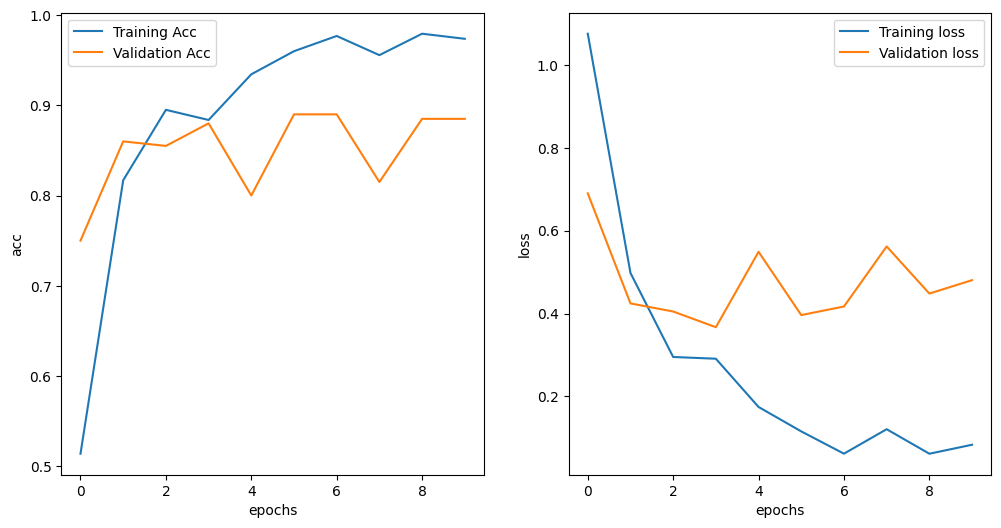

In [10]:
# Plot Evaluation Metrics
plt.figure(figsize=(12, 6))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Acc')
plt.plot(history.history['val_accuracy'], label='Validation Acc')
plt.xlabel('epochs')
plt.ylabel('acc')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()

plt.show()